# Lab 4.4: Inside a Tiny Transformer

Chapter 4, Inside Deep Networks and Transformers. You will train a two-layer transformer on a lookup task, look at its attention patterns, and then test whether a pattern is a faithful explanation by editing the input. Everything runs on a laptop CPU; each training run takes under a minute. The data are generated in the notebook.

The task: the model reads four key and value pairs, such as `B 9 E 0 C 2 D 3`, then `?` and one of the keys, such as `C`. It must output the value that followed that key (here `2`).

In [1]:
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
torch.manual_seed(0)
print("torch", torch.__version__, "numpy", np.__version__)

KEYS = list("ABCDEFGH")
VOCAB = KEYS + [str(i) for i in range(10)] + ["?"]
QMARK = VOCAB.index("?")

def make_batch(n, g, n_pairs=4):
    T = 2 * n_pairs + 2
    ks = np.argsort(g.random((n, len(KEYS))), axis=1)[:, :n_pairs]   # distinct keys
    vs = g.integers(0, 10, (n, n_pairs))
    X = np.zeros((n, T), dtype=np.int64)
    X[:, 0:2 * n_pairs:2] = ks
    X[:, 1:2 * n_pairs:2] = len(KEYS) + vs
    X[:, -2] = QMARK
    j = g.integers(0, n_pairs, n)
    X[:, -1] = ks[np.arange(n), j]
    y = len(KEYS) + vs[np.arange(n), j]
    return torch.tensor(X), torch.tensor(y)

X, y = make_batch(1, np.random.default_rng(5))
print([VOCAB[i] for i in X[0]], "->", VOCAB[y[0]])

torch 2.6.0 numpy 2.2.6
['H', '0', 'E', '0', 'D', '1', 'F', '9', '?', 'H'] -> 0


## 1. The model

Two layers, each with an attention block (two heads) and an MLP block, both adding into the residual stream. The attention block stores its weights so we can look at them.

In [2]:
class Attention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.h, self.dk = heads, d // heads
        self.q, self.k, self.v, self.o = (nn.Linear(d, d, bias=False) for _ in range(4))
    def forward(self, x):
        B, T, d = x.shape
        split = lambda t: t.view(B, T, self.h, self.dk).transpose(1, 2)
        q, k, v = split(self.q(x)), split(self.k(x)), split(self.v(x))
        scores = (q @ k.transpose(-1, -2)) / self.dk ** 0.5
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)        # no peeking ahead
        a = scores.masked_fill(mask, -1e9).softmax(-1)
        self.weights, self.values = a.detach(), v.detach()
        return self.o((a @ v).transpose(1, 2).reshape(B, T, d))

class TinyTransformer(nn.Module):
    def __init__(self, T, d=64, heads=2, layers=2):
        super().__init__()
        self.emb = nn.Embedding(len(VOCAB), d)
        self.pos = nn.Parameter(torch.randn(T, d) * 0.1)
        self.att = nn.ModuleList([Attention(d, heads) for _ in range(layers)])
        self.mlp = nn.ModuleList([nn.Sequential(nn.Linear(d, 4 * d), nn.ReLU(), nn.Linear(4 * d, d)) for _ in range(layers)])
        self.ln = nn.ModuleList([nn.LayerNorm(d) for _ in range(2 * layers)])
        self.ln_f, self.unembed = nn.LayerNorm(d), nn.Linear(d, len(VOCAB))
    def forward(self, x):
        r = self.emb(x) + self.pos                       # the residual stream starts here
        for i in range(len(self.att)):
            r = r + self.att[i](self.ln[2 * i](r))       # attention reads and adds
            r = r + self.mlp[i](self.ln[2 * i + 1](r))   # MLP reads and adds
        return self.unembed(self.ln_f(r))[:, -1]         # scores for the answer

def train(n_pairs=4, steps=800, seed=0):
    torch.manual_seed(seed)
    g = np.random.default_rng(seed)
    model = TinyTransformer(T=2 * n_pairs + 2)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
    for step in range(steps):
        X, y = make_batch(256, g, n_pairs)
        loss = nn.functional.cross_entropy(model(X), y)
        opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    return model

## 2. Train and check accuracy

**Checkpoint 1:** test accuracy on 2,000 new sequences is 1.00 (or very close).

In [3]:
import time
t0 = time.time()
model = train()
Xt, yt = make_batch(2000, np.random.default_rng(1))
with torch.no_grad():
    acc = (model(Xt).argmax(-1) == yt).float().mean().item()
print(f"test accuracy {acc:.3f}  (trained in {time.time() - t0:.0f} s)")

test accuracy 1.000  (trained in 27 s)


## 3. Look at the attention

**Checkpoint 2:** in layer 2, the last row (the query position `C`) puts almost all its weight on the token `2`. In layer 1, the weights are spread out.

prediction: 2


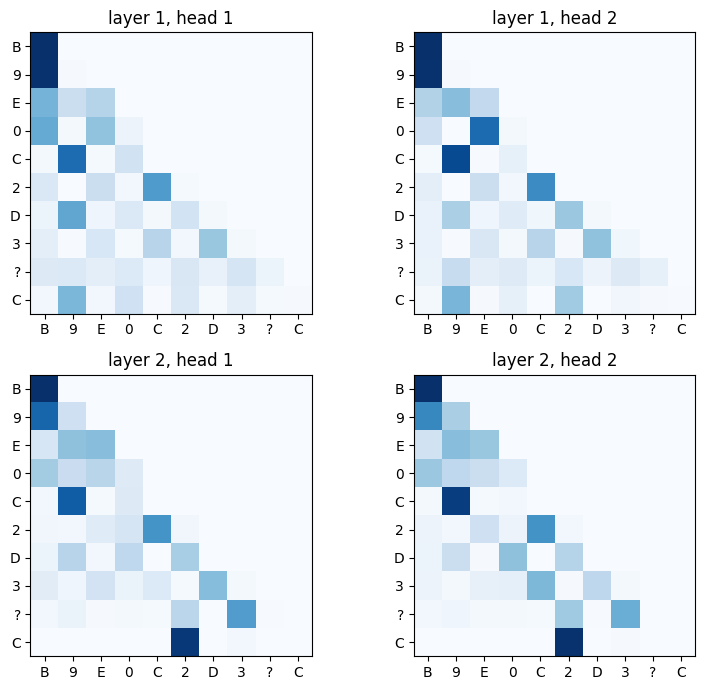

layer 1 head 1, last row: [0.03 0.46 0.03 0.2  0.   0.14 0.01 0.1  0.02 0.01]
layer 1 head 2, last row: [0.02 0.47 0.01 0.09 0.   0.36 0.   0.03 0.01 0.01]
layer 2 head 1, last row: [0.   0.   0.   0.   0.   0.97 0.   0.03 0.   0.  ]
layer 2 head 2, last row: [0.   0.   0.   0.   0.   0.99 0.   0.01 0.   0.  ]


In [4]:
ex = torch.tensor([[1, 8 + 9, 4, 8 + 0, 2, 8 + 2, 3, 8 + 3, QMARK, 2]])   # B 9 E 0 C 2 D 3 ? C
toks = [VOCAB[i] for i in ex[0]]
with torch.no_grad():
    pred = VOCAB[model(ex).argmax(-1).item()]
print("prediction:", pred)
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for L in range(2):
    for h in range(2):
        ax = axes[L, h]
        ax.imshow(model.att[L].weights[0, h].numpy(), cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks)
        ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks)
        ax.set_title(f"layer {L + 1}, head {h + 1}")
plt.tight_layout(); plt.show()
for L in range(2):
    for h in range(2):
        print(f"layer {L + 1} head {h + 1}, last row:", model.att[L].weights[0, h, -1].numpy().round(2))

## 4. Across the test set

**Checkpoint 3:** averaged over heads, layer 2 puts about 0.9 or more of the last position's attention on the correct value.

In [5]:
def answer_position(X, n_pairs=4):
    return 2 * (X[:, :2 * n_pairs:2] == X[:, -1:]).float().argmax(1) + 1

with torch.no_grad():
    model(Xt)
pos = answer_position(Xt)
for L in range(2):
    w = model.att[L].weights.mean(1)[:, -1]          # average over heads, last row
    print(f"layer {L + 1}: mean attention on the answer value = {w[torch.arange(len(Xt)), pos].mean():.3f}")

layer 1: mean attention on the answer value = 0.179
layer 2: mean attention on the answer value = 0.940


## 5. Test the pattern by editing

If layer 2 really retrieves the answer from the attended token, then changing that token should change the answer, and changing a different value token should not. **Checkpoint 4:** about 100 percent of answers change when the attended value is edited, and about 0 percent when another value is edited.

In [6]:
def edit_rate(model, X, positions, seed=0):
    g = torch.Generator().manual_seed(seed)
    Xe = X.clone(); idx = torch.arange(len(X))
    old = Xe[idx, positions] - len(KEYS)
    new = (old + 1 + torch.randint(0, 9, (len(X),), generator=g)) % 10      # always a different value
    Xe[idx, positions] = len(KEYS) + new
    with torch.no_grad():
        return (model(Xe).argmax(-1) != model(X).argmax(-1)).float().mean().item()

other = torch.where(pos == 1, torch.full_like(pos, 3), torch.full_like(pos, 1))
print("edit the attended value:", round(edit_rate(model, Xt, pos), 3))
print("edit another value:     ", round(edit_rate(model, Xt, other), 3))

edit the attended value: 1.0


edit another value:      0.0


## 6. Weight versus contribution (Kobayashi et al., 2020)

The chapter's Deep box showed that a token can receive weight and still contribute little. Here we compute, for the last position in each head, the attention weight times the size of what the head would write from each token. **Checkpoint 5:** for layer 2 the two views agree closely; look at layer 1 and note any position where they disagree.

In [7]:
with torch.no_grad():
    model(ex)
for L in range(2):
    att = model.att[L]
    Wo = att.o.weight.detach()
    for h in range(2):
        v = att.values[0, h]                                  # (T, dk)
        written = v @ Wo[:, h * att.dk:(h + 1) * att.dk].T    # what each token would write
        size = written.norm(dim=-1)
        w = att.weights[0, h, -1]
        contrib = (w * size) / (w * size).sum()
        print(f"layer {L + 1} head {h + 1}")
        print("   weight      ", w.numpy().round(2))
        print("   contribution", contrib.numpy().round(2))

layer 1 head 1
   weight       [0.03 0.46 0.03 0.2  0.   0.14 0.01 0.1  0.02 0.01]
   contribution [0.04 0.4  0.04 0.25 0.01 0.13 0.02 0.09 0.01 0.02]
layer 1 head 2
   weight       [0.02 0.47 0.01 0.09 0.   0.36 0.   0.03 0.01 0.01]
   contribution [0.04 0.42 0.02 0.08 0.   0.38 0.   0.03 0.01 0.01]
layer 2 head 1
   weight       [0.   0.   0.   0.   0.   0.97 0.   0.03 0.   0.  ]
   contribution [0.   0.   0.   0.   0.   0.95 0.   0.04 0.   0.  ]
layer 2 head 2
   weight       [0.   0.   0.   0.   0.   0.99 0.   0.01 0.   0.  ]
   contribution [0.   0.   0.   0.   0.   0.99 0.   0.01 0.   0.  ]


## 7. A variant: six pairs instead of four

Retrain with six key and value pairs and repeat the editing test. **Checkpoint 6:** accuracy should again be high; report it, and report both edit rates. If accuracy is lower, say whether the attention pattern still predicts what editing does.

In [8]:
model6 = train(n_pairs=6, steps=1200)
X6, y6 = make_batch(2000, np.random.default_rng(2), n_pairs=6)
with torch.no_grad():
    acc6 = (model6(X6).argmax(-1) == y6).float().mean().item()
pos6 = answer_position(X6, 6)
other6 = torch.where(pos6 == 1, torch.full_like(pos6, 3), torch.full_like(pos6, 1))
print(f"accuracy {acc6:.3f}")
print("edit the attended value:", round(edit_rate(model6, X6, pos6), 3))
print("edit another value:     ", round(edit_rate(model6, X6, other6), 3))

accuracy 1.000
edit the attended value: 1.0


edit another value:      0.0


## What to hand in

1. The two layer-2 heatmaps from Section 3 and one layer-1 heatmap.
2. The edit rates from Sections 5 and 7.
3. A paragraph: which head would you trust as an explanation of the answer, which one would you not, and why. Use the words *faithful* and *tested*.